In [1]:
import glob
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.stats.anova import AnovaRM

In [2]:
sequences = pd.read_csv('../data/interim/sequences_sample_50.csv')
sequences['index'] = sequences['index'].apply(str)
sequences = sequences.set_index('index')
sequences['type'] = sequences['label'].map(lambda label: 'binder' if label else 'decoy')

In [3]:
with open('../data/interim/sequence_key.txt') as fh:
    sequence_key = {sequence: key for key, sequence in (line.split() for line in fh if line)}

In [4]:
full_sequences = pd.read_csv('../data/interim/sequences_full.csv')
full_sequences['id'] = full_sequences['id'].apply(str)
full_sequences = full_sequences.set_index('id')

In [5]:
msa_ids = set(full_sequences.melt(ignore_index=False)['value'].map(sequence_key).dropna().loc[sequences.index].tolist())

In [6]:
timings = []
for path in glob.glob('../data/benchmarks/msa-generation_*.tsv'):
    timing = pd.read_csv(path, delimiter='\t')

    method_info = re.search(
        'msa-generation_(?P<msa_method>[a-zA-Z0-9]+)(?:_(?P<data_source>[a-zA-Z0-9]+))?_(?P<id>[a-zA-Z0-9]+).tsv', path
    ).groupdict()

    for key, val in method_info.items():
        timing[key] = val

    timings.append(timing)

timings = pd.concat(timings).reset_index(drop=True)
timings = timings[timings['id'].isin(msa_ids)].copy()

In [7]:
def format_time(seconds: int) -> str:
    hours = seconds // 3600
    minutes = (seconds % 3600) // 60
    secs = seconds % 60
    parts = []
    if hours > 0:
        parts.append(f'{int(hours)} hours')

    if minutes > 0:
        parts.append(f'{int(minutes)} mins')

    if secs > 0 or not parts:
        parts.append(f'{int(secs)} secs')

    return ', '.join(parts)

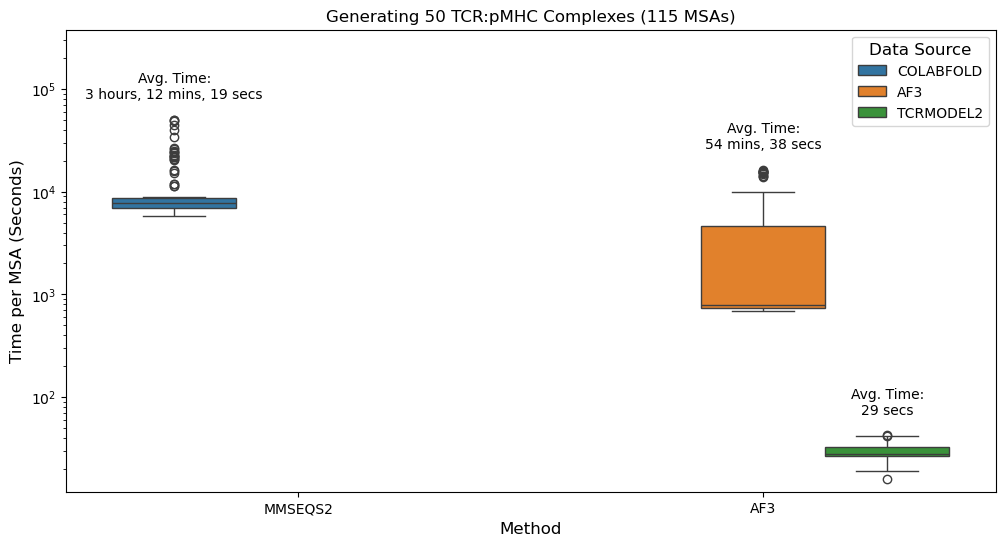

In [8]:
plt.figure(figsize=(12, 6))
plt.title('Generating 50 TCR:pMHC Complexes (115 MSAs)')

ax = sns.boxplot(timings, y='s', x='msa_method', hue='data_source')
ax.set(yscale='log')

ax.set_xlabel('Method', fontsize=12)
ax.set_ylabel('Time per MSA (Seconds)', fontsize=12)


groups = timings.groupby(['msa_method', 'data_source'])

x_labels = [tick_label.get_text() for tick_label in ax.get_xticklabels()]
handles, hue_labels = ax.get_legend_handles_labels()

n_x = len(x_labels)
n_hue = len(hue_labels)
positions = np.arange(n_x)

total_width = 0.8
box_width = total_width / n_hue

for i, x_label in enumerate(x_labels):
    for j, hue_label in enumerate(hue_labels):
        if (x_label, hue_label) not in groups.groups:
            continue

        group = groups.get_group((x_label, hue_label))
        x_pos = positions[i] - total_width / 2 + box_width * (j + 0.5)

        ax.text(
            x_pos,
            group['s'].max() * 1.5,
            f"Avg. Time:\n{format_time(group['s'].mean())}",
            ha='center',
            va='bottom',
        )

leg = ax.legend(title='Data Source', title_fontsize=12)
for text in leg.get_texts():
    text.set_text(text.get_text().upper())

ax.set_ylim(timings['s'].min() * 0.75, timings['s'].max() * 7.5)
ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()])

plt.show()

In [9]:
confidences = []
for path in glob.glob('../data/processed/confidence_scores_*_50.csv'):
    confidence_scores = pd.read_csv(path)
    info = re.search(
        r'confidence_scores_(?P<msa_method>[a-zA-Z0-9]+)_(?P<data_source>[a-zA-Z0-9]+)_(?P<sample_size>\d+).csv',
        os.path.basename(path),
    )

    for key, value in info.groupdict().items():
        confidence_scores[key] = value

    confidences.append(confidence_scores)

confidences = pd.concat(confidences)
confidences['structure_name'] = confidences['structure_name'].apply(str)

In [10]:
confidences = confidences.merge(sequences, how='left', left_on='structure_name', right_on='index')

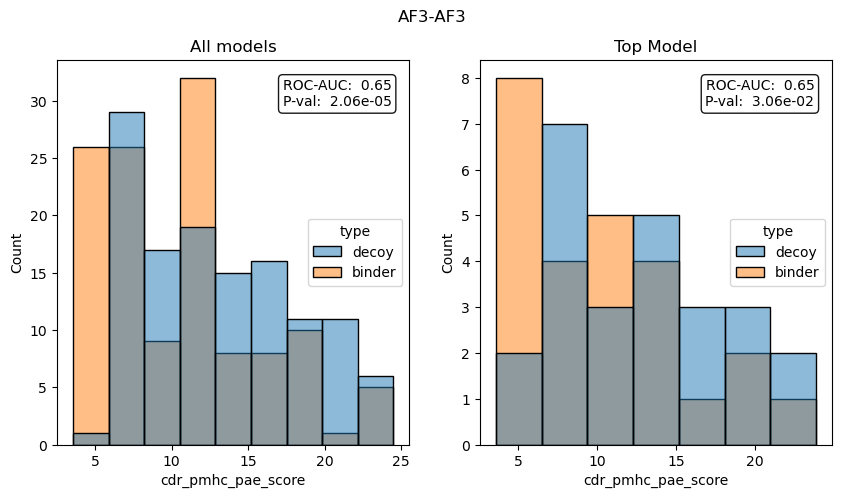

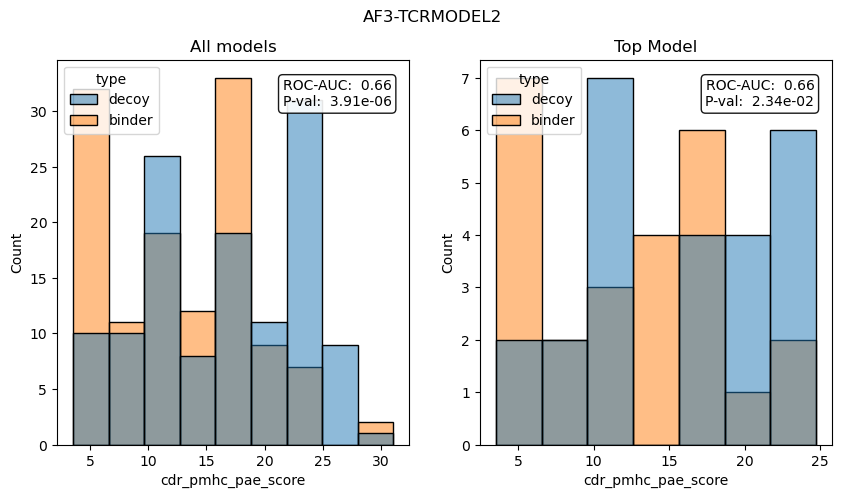

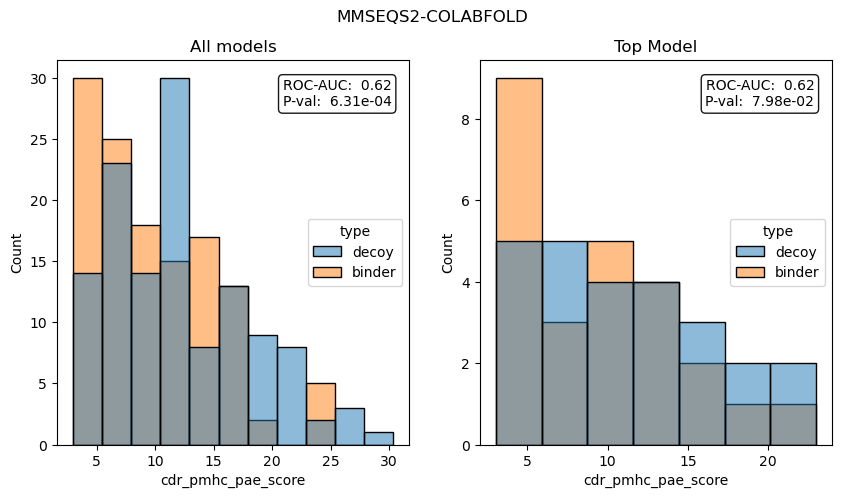

In [11]:
for name, group in confidences.groupby(['msa_method', 'data_source']):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))
    fig.suptitle('-'.join(name).upper())

    sns.histplot(group, x='cdr_pmhc_pae_score', hue='type', ax=ax1)
    ax1.set_title('All models')

    roc_auc = 1 - roc_auc_score(group['label'], group['cdr_pmhc_pae_score'])
    stat, p_val = stats.ranksums(
        group.query("type == 'binder'")['cdr_pmhc_pae_score'],
        group.query("type == 'decoy'")['cdr_pmhc_pae_score'],
        alternative='less',
    )
    ax1.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc_auc: .2f}\nP-val: {p_val: .2e}',
        transform=ax1.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

    group_top_model = group.query('top_model')
    sns.histplot(group_top_model, x='cdr_pmhc_pae_score', hue='type', ax=ax2)
    ax2.set_title('Top Model')

    roc_auc_top_model = 1 - roc_auc_score(group_top_model['label'], group_top_model['cdr_pmhc_pae_score'])
    stat_top_model, p_val_top_model = stats.ranksums(
        group_top_model.query("type == 'binder'")['cdr_pmhc_pae_score'],
        group_top_model.query("type == 'decoy'")['cdr_pmhc_pae_score'],
        alternative='less',
    )
    ax2.text(
        0.95,
        0.95,
        f'ROC-AUC: {roc_auc_top_model: .2f}\nP-val: {p_val_top_model: .2e}',
        transform=ax2.transAxes,
        verticalalignment='top',
        horizontalalignment='right',
        bbox={'boxstyle': 'round', 'facecolor': 'white', 'alpha': 0.90},
    )

In [12]:
NUM_SAMPLES = 15
SAMPLE_SIZE = 20

rng = np.random.default_rng(123)

structure_names = sorted(confidences['structure_name'].unique())

roc_aucs = {
    'sample_number': [],
    'msa_method': [],
    'data_source': [],
    'roc_auc': [],
    'roc_auc_top': [],
}

for sample_number in range(1, NUM_SAMPLES + 1):
    sampled_structure_names = rng.choice(structure_names, SAMPLE_SIZE, replace=False)

    for (msa_method, data_source), group in confidences.groupby(['msa_method', 'data_source']):
        sample = group[group['structure_name'].isin(sampled_structure_names)]
        sample_top_model = sample.query('top_model')

        roc_aucs['sample_number'].append(sample_number)
        roc_aucs['msa_method'].append(msa_method)
        roc_aucs['data_source'].append(data_source)
        roc_aucs['roc_auc'].append(1 - roc_auc_score(sample['label'], sample['cdr_pmhc_pae_score']))
        roc_aucs['roc_auc_top'].append(
            1 - roc_auc_score(sample_top_model['label'], sample_top_model['cdr_pmhc_pae_score'])
        )

roc_aucs = pd.DataFrame(roc_aucs)

In [13]:
roc_aucs = roc_aucs.melt(
    id_vars=['sample_number', 'msa_method', 'data_source'],
    value_vars=['roc_auc', 'roc_auc_top'],
    var_name='type',
    value_name='score',
)
roc_aucs['type'] = roc_aucs['type'].map({'roc_auc': 'all', 'roc_auc_top': 'top'})

In [14]:
roc_aucs['msa_method_data_source'] = roc_aucs['msa_method'] + '-' + roc_aucs['data_source']

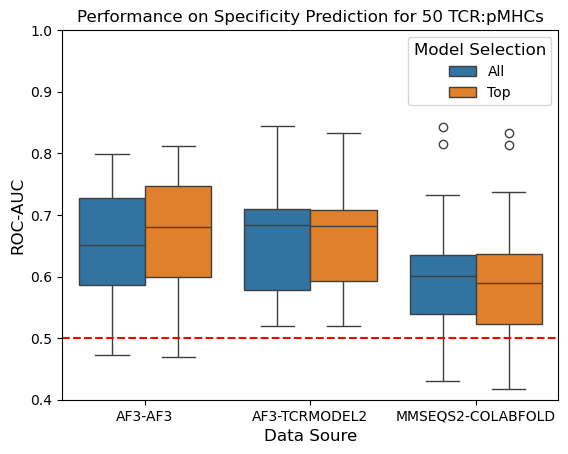

In [15]:
ax = sns.boxplot(roc_aucs, x='msa_method_data_source', y='score', hue='type')

ax.axhline(0.5, color='red', linestyle='dashed')

ax.set_ylim((0.40, 1.0))

ax.set_ylabel('ROC-AUC', fontsize=12)
ax.set_xlabel('Data Soure', fontsize=12)

ax.set_xticks(ax.get_xticks())
ax.set_xticklabels([label.get_text().upper() for label in ax.get_xticklabels()])

handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [label.title() for label in labels], title='Model Selection', title_fontsize=12)

ax.set_title('Performance on Specificity Prediction for 50 TCR:pMHCs', fontsize=12)

plt.show()

In [16]:
aovrm = AnovaRM(roc_aucs, depvar='score', subject='sample_number', within=['msa_method_data_source', 'type'])
res = aovrm.fit()
print(res)

                          Anova
                            F Value Num DF  Den DF Pr > F
---------------------------------------------------------
msa_method_data_source       2.7570 2.0000 28.0000 0.0807
type                         1.8102 1.0000 14.0000 0.1999
msa_method_data_source:type  4.5988 2.0000 28.0000 0.0187

